In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import warnings

warnings.filterwarnings("ignore")

Load dataset

In [3]:
import pandas as pd

df = pd.read_csv("../dataset/REL_v50_database_20230527.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (1084, 21)


,projectile,proj_type,calibre,proj_mass,proj_density,proj_hardness,Material,thickness,density,modulus,...,yield,PR,UTS,elongation,Ludwik-n,angle,v50,sigma_mps,ind_data,source
0,CAL30APM2,AP,6.2484,5.3,7.85,570,AA6070-O,20,2.71,70.0,...,70.0,0.33,145.0,20.0,0.175,0,348,NaN,Y,forrestal_21_jdbm
1,CAL30APM2,AP,6.2484,5.3,7.85,570,AA6070-T4,20,2.71,70.0,...,170.0,0.33,320.0,20.0,0.192,0,506,NaN,Y,forrestal_21_jdbm
2,CAL30APM2,AP,6.2484,5.3,7.85,570,AA6082-T6,10,2.70,70.0,...,260.0,0.33,290.0,10.0,0.070,0,347,NaN,N,forrestal_21_jdbm
3,CAL30APM2,AP,6.2484,5.3,7.85,570,AA6082-T6,20,2.70,70.0,...,260.0,0.33,290.0,10.0,0.070,0,501,NaN,Y,forrestal_14_expmech
4,CAL30APM2,AP,6.2484,5.3,7.85,570,AA6082-T6,20,2.70,70.0,...,260.0,0.33,290.0,10.0,0.070,15,516,NaN,Y,forrestal_14_expmech


In [4]:
print("Columns:")
for i, col in enumerate(df.columns, 1):
    print(i, "->", col)

Columns:
1 -> projectile
2 -> proj_type
3 -> calibre
4 -> proj_mass
5 -> proj_density
6 -> proj_hardness
7 -> Material
8 -> thickness
9 -> density
10 -> modulus
11 -> hardness
12 -> yield
13 -> PR
14 -> UTS
15 -> elongation
16 -> Ludwik-n
17 -> angle
18 -> v50
19 -> sigma_mps
20 -> ind_data
21 -> source


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1084 entries, 0 to 1083
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   projectile     1084 non-null   object 
 1   proj_type      1084 non-null   object 
 2   calibre        1084 non-null   float64
 3   proj_mass      1084 non-null   float64
 4   proj_density   1084 non-null   float64
 5   proj_hardness  1084 non-null   int64  
 6   Material       1084 non-null   object 
 7   thickness      1084 non-null   object 
 8   density        1084 non-null   float64
 9   modulus        1084 non-null   float64
 10  hardness       1084 non-null   object 
 11  yield          1084 non-null   float64
 12  PR             1084 non-null   float64
 13  UTS            1084 non-null   float64
 14  elongation     1084 non-null   float64
 15  Ludwik-n       1084 non-null   float64
 16  angle          1084 non-null   object 
 17  v50            1084 non-null   object 
 18  sigma_mp

In [6]:
print("\nDataset Shape:")
print(df.shape)

print("\nNumber of Rows:", len(df))
print("Number of Columns:", len(df.columns))


Dataset Shape:
(1084, 21)

Number of Rows: 1084
Number of Columns: 21


Check Missing values

In [7]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing Values": missing.values,
    "Missing %": (missing.values / len(df)) * 100
})

missing_df = missing_df.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_df)

,Column,Missing Values,Missing %
18,sigma_mps,559,51.568266
0,projectile,0,0.000000
11,yield,0,0.000000
19,ind_data,0,0.000000
17,v50,0,0.000000
16,angle,0,0.000000
15,Ludwik-n,0,0.000000
14,elongation,0,0.000000
13,UTS,0,0.000000
12,PR,0,0.000000


In [8]:
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 49


Convert numeric columns 

In [9]:
numeric_columns = [
    "calibre",
    "proj_mass",
    "proj_density",
    "proj_hardness",
    "thickness",
    "density",
    "modulus",
    "hardness",
    "yield",
    "PR",
    "UTS",
    "elongation",
    "Ludwik-n",
    "angle",
    "v50",
    "sigma_mps"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [10]:
print(df.dtypes)

projectile        object
proj_type         object
calibre          float64
proj_mass        float64
proj_density     float64
proj_hardness      int64
Material          object
thickness        float64
density          float64
modulus          float64
hardness         float64
yield            float64
PR               float64
UTS              float64
elongation       float64
Ludwik-n         float64
angle            float64
v50              float64
sigma_mps        float64
ind_data          object
source            object
dtype: object


Check target v50

In [11]:
print("Missing v50:", df["v50"].isna().sum())

print("\nV50 Statistics:")
print(df["v50"].describe())

Missing v50: 24

V50 Statistics:
count    1060.000000
mean      745.539623
std       151.198440
min       162.000000
25%       669.750000
50%       738.000000
75%       833.000000
max      1451.000000
Name: v50, dtype: float64


Remove rows without target

In [12]:
df_model = df.dropna(subset=["v50"]).copy()

print("Original dataset:", df.shape)
print("Dataset available for V50 prediction:", df_model.shape)

Original dataset: (1084, 21)
Dataset available for V50 prediction: (1060, 21)


# EDA

V50 distribution

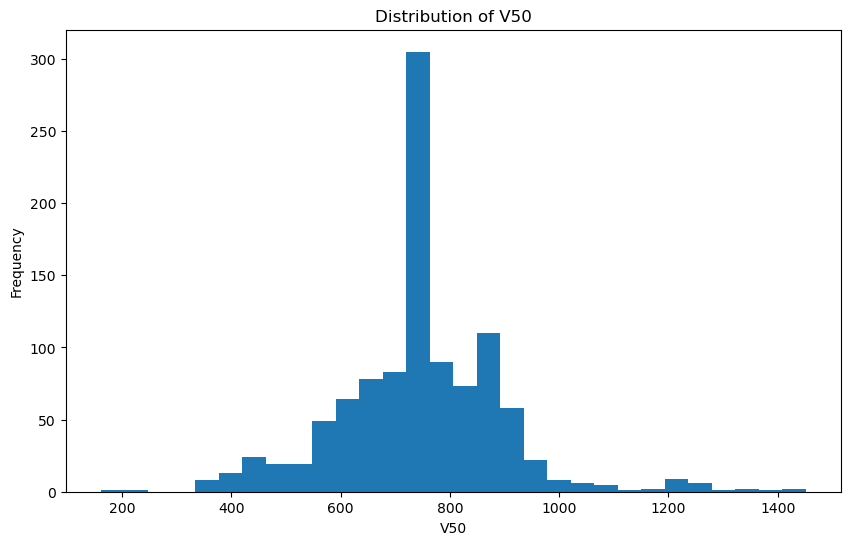

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(df_model["v50"], bins=30)

plt.xlabel("V50")
plt.ylabel("Frequency")
plt.title("Distribution of V50")

plt.show()

V50 vs projectile mass

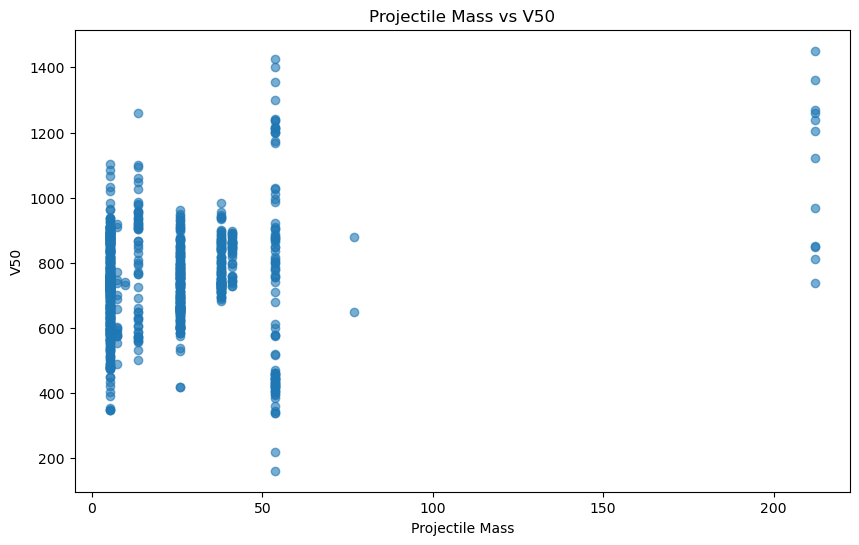

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_model["proj_mass"],
    df_model["v50"],
    alpha=0.6
)

plt.xlabel("Projectile Mass")
plt.ylabel("V50")
plt.title("Projectile Mass vs V50")

plt.show()

V50 vs target thickness

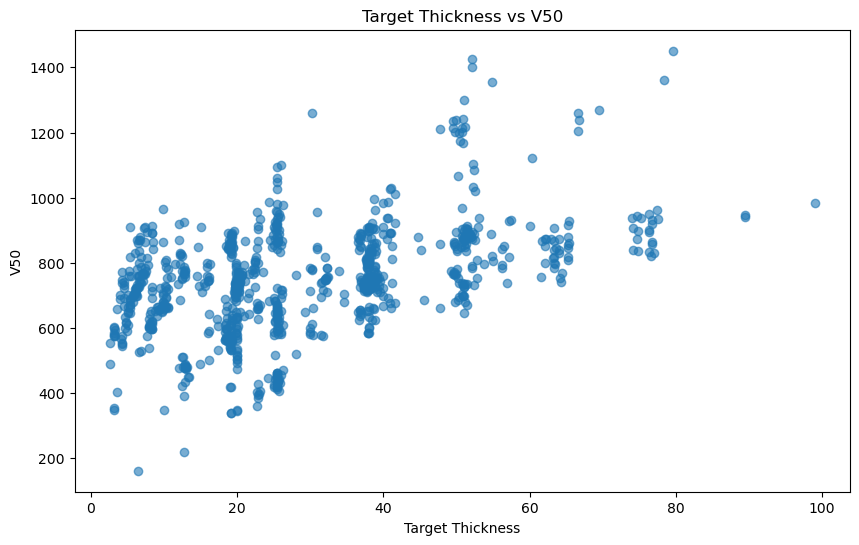

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_model["thickness"],
    df_model["v50"],
    alpha=0.6
)

plt.xlabel("Target Thickness")
plt.ylabel("V50")
plt.title("Target Thickness vs V50")

plt.show()

V50 vs impact angle

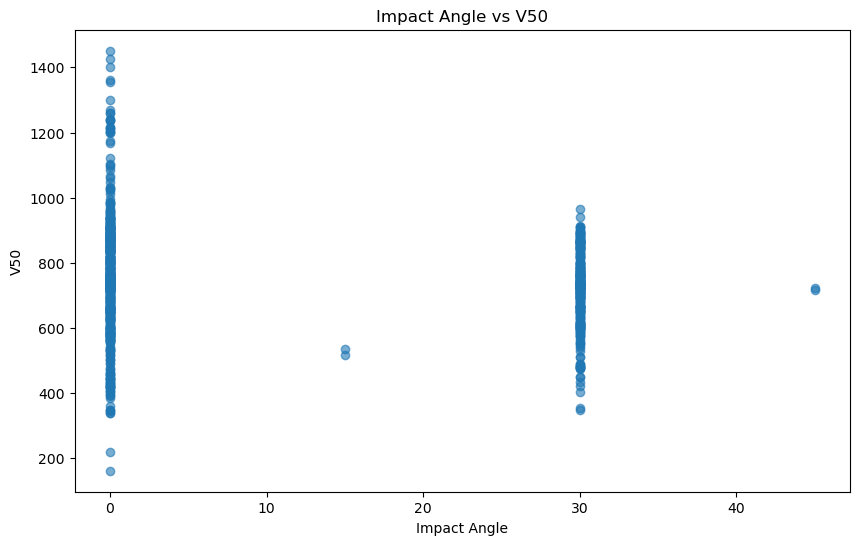

In [16]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df_model["angle"],
    df_model["v50"],
    alpha=0.6
)

plt.xlabel("Impact Angle")
plt.ylabel("V50")
plt.title("Impact Angle vs V50")

plt.show()

V50 by projectile type

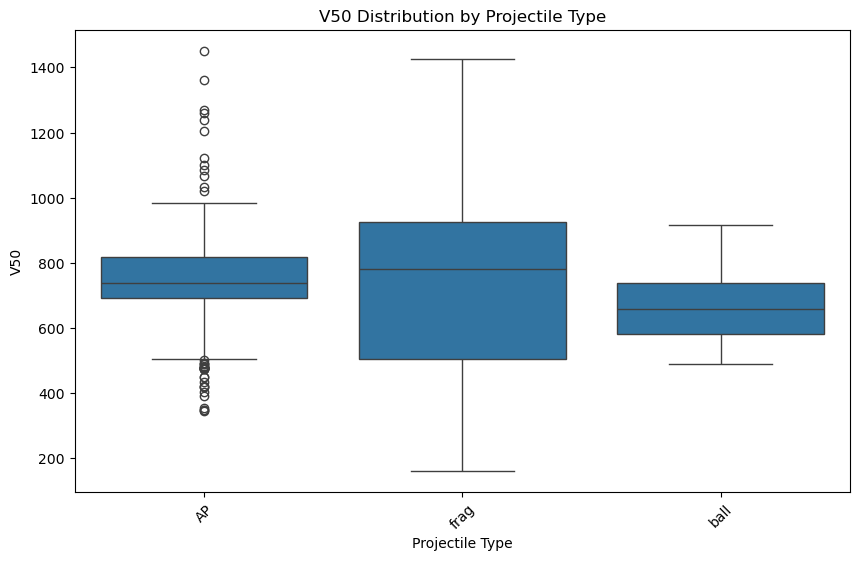

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_model,
    x="proj_type",
    y="v50"
)

plt.xlabel("Projectile Type")
plt.ylabel("V50")
plt.title("V50 Distribution by Projectile Type")

plt.xticks(rotation=45)

plt.show()

V50 by target material

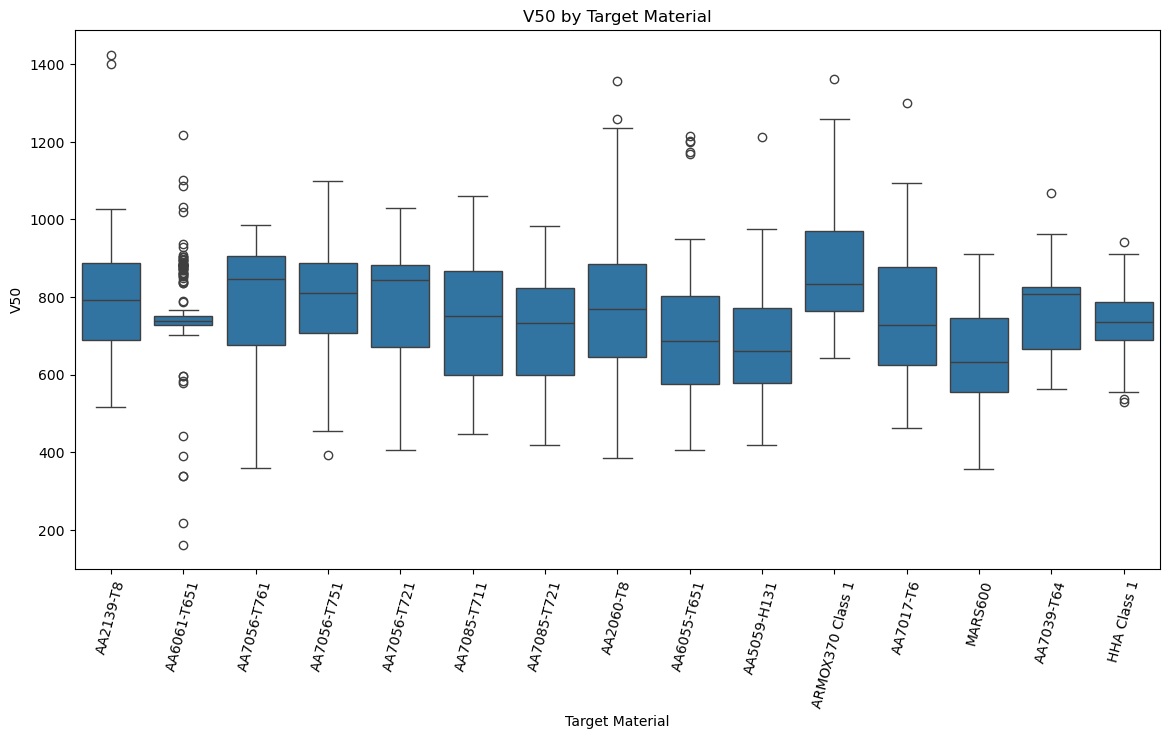

In [18]:
top_materials = (
    df_model["Material"]
    .value_counts()
    .head(15)
    .index
)

material_df = df_model[
    df_model["Material"].isin(top_materials)
]

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=material_df,
    x="Material",
    y="v50"
)

plt.xticks(rotation=75)

plt.xlabel("Target Material")
plt.ylabel("V50")

plt.title("V50 by Target Material")

plt.show()

Correlation analysis

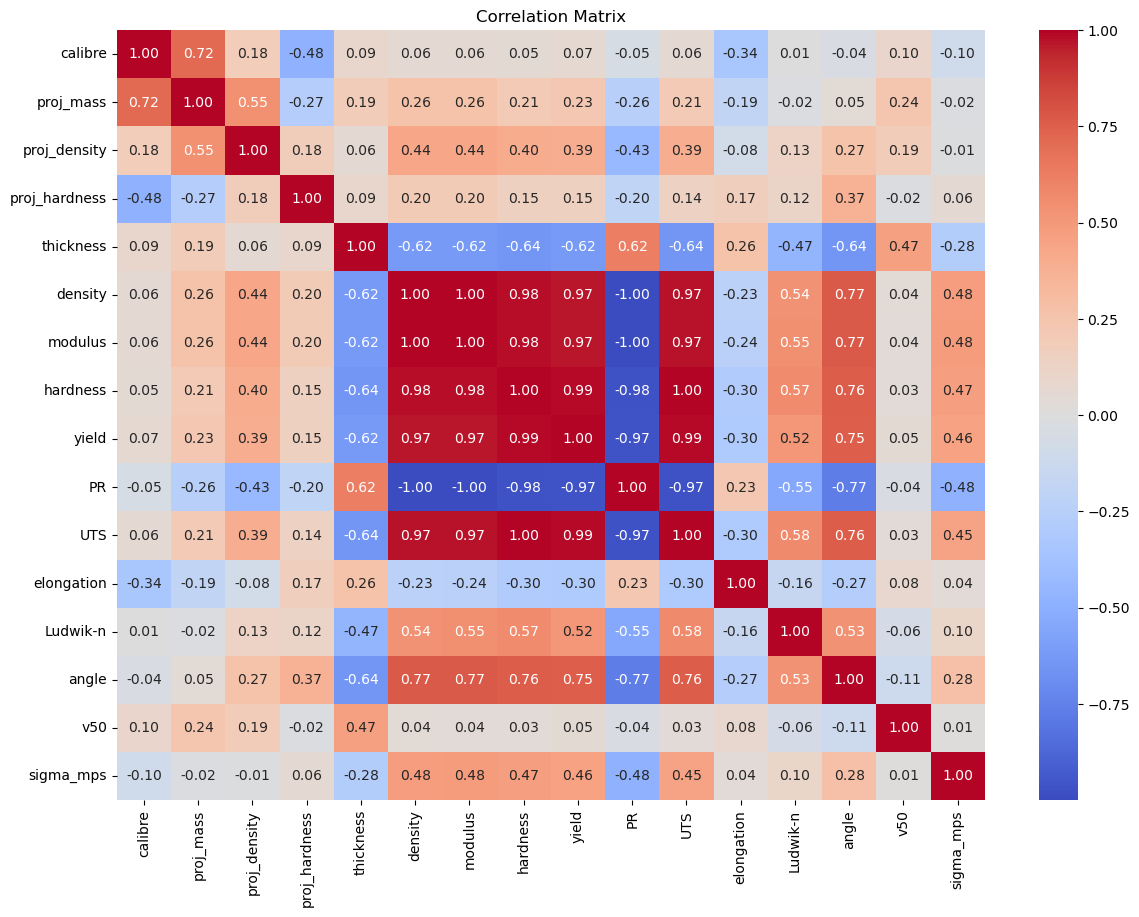

In [19]:
numeric_df = df_model.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

Define ML features

In [20]:
features = [
    "proj_type",
    "calibre",
    "proj_mass",
    "proj_density",
    "proj_hardness",
    "Material",
    "thickness",
    "density",
    "modulus",
    "hardness",
    "yield",
    "PR",
    "UTS",
    "elongation",
    "Ludwik-n",
    "angle"
]

X = df_model[features]
y = df_model["v50"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1060, 16)
y shape: (1060,)


Identify categorical and numerical columns

In [21]:
categorical_features = [
    "proj_type",
    "Material"
]

numerical_features = [
    "calibre",
    "proj_mass",
    "proj_density",
    "proj_hardness",
    "thickness",
    "density",
    "modulus",
    "hardness",
    "yield",
    "PR",
    "UTS",
    "elongation",
    "Ludwik-n",
    "angle"
]

Train-test split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (848, 16)
Testing data: (212, 16)


Preprocessing pipeline

In [23]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

Model 1 — Linear Regression

In [24]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [25]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("-------------------------")
print("MAE :", linear_mae)
print("MSE :", linear_mse)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression
-------------------------
MAE : 64.44217134773754
MSE : 9629.200269121518
RMSE: 98.12848857045297
R²  : 0.6062038597253762


Model 2 — Decision Tree

In [26]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=10
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

tree_pred = decision_tree_model.predict(X_test)

In [27]:
tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree")
print("-------------------------")
print("MAE :", tree_mae)
print("MSE :", tree_mse)
print("RMSE:", tree_rmse)
print("R²  :", tree_r2)

Decision Tree
-------------------------
MAE : 33.43625106752458
MSE : 3641.1195268166275
RMSE: 60.34168979086207
R²  : 0.8510926374086345


Model 3 — Random Forest

In [28]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            max_depth=15,
            min_samples_split=3,
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

rf_pred = random_forest_model.predict(X_test)

In [29]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print("-------------------------")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
-------------------------
MAE : 27.621369914826218
MSE : 2096.3828780712943
RMSE: 45.78627390464629
R²  : 0.9142662461212265


Model 4 — Gradient Boosting

In [30]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_model.fit(X_train, y_train)

gradient_pred = gradient_model.predict(X_test)

In [31]:
gradient_mae = mean_absolute_error(
    y_test,
    gradient_pred
)

gradient_mse = mean_squared_error(
    y_test,
    gradient_pred
)

gradient_rmse = np.sqrt(gradient_mse)

gradient_r2 = r2_score(
    y_test,
    gradient_pred
)

print("Gradient Boosting")
print("-------------------------")
print("MAE :", gradient_mae)
print("MSE :", gradient_mse)
print("RMSE:", gradient_rmse)
print("R²  :", gradient_r2)

Gradient Boosting
-------------------------
MAE : 35.62969460582077
MSE : 2554.147173192442
RMSE: 50.53857114316195
R²  : 0.8955455001053492


Compare all models

In [32]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae,
        gradient_mae
    ],

    "MSE": [
        linear_mse,
        tree_mse,
        rf_mse,
        gradient_mse
    ],

    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse,
        gradient_rmse
    ],

    "R2": [
        linear_r2,
        tree_r2,
        rf_r2,
        gradient_r2
    ]
})

results = results.sort_values(
    by="RMSE",
    ascending=True
)

display(results)

,Model,MAE,MSE,RMSE,R2
2,Random Forest,27.621370,2096.382878,45.786274,0.914266
3,Gradient Boosting,35.629695,2554.147173,50.538571,0.895546
1,Decision Tree,33.436251,3641.119527,60.341690,0.851093
0,Linear Regression,64.442171,9629.200269,98.128489,0.606204


In [33]:
best_model_name = results.iloc[0]["Model"]

print("Best model:", best_model_name)

Best model: Random Forest


Actual vs Predicted graph

In [34]:
predictions = {
    "Linear Regression": linear_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gradient_pred
}

best_predictions = predictions[best_model_name]

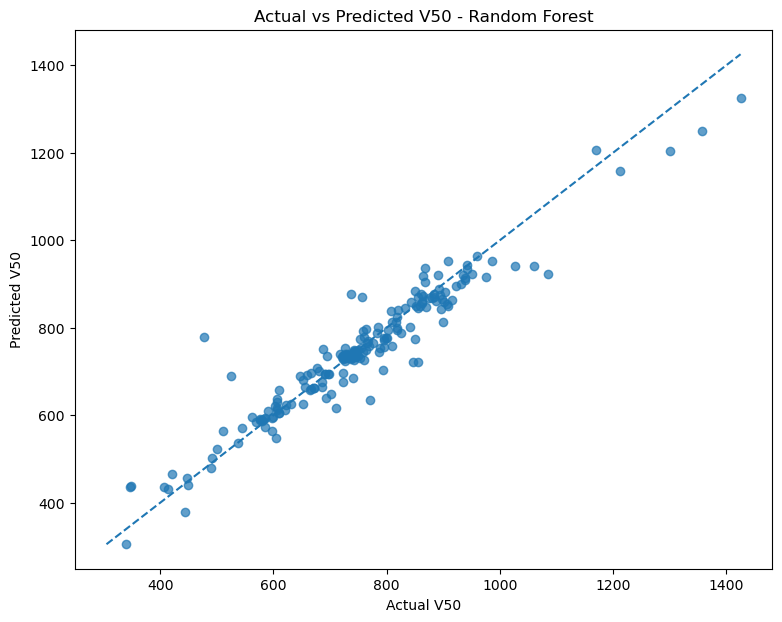

In [35]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

plt.xlabel("Actual V50")
plt.ylabel("Predicted V50")

plt.title(
    f"Actual vs Predicted V50 - {best_model_name}"
)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

Calculate prediction error

In [36]:
evaluation_df = pd.DataFrame({
    "Actual_V50": y_test.values,
    "Predicted_V50": best_predictions
})

evaluation_df["Error"] = (
    evaluation_df["Actual_V50"]
    - evaluation_df["Predicted_V50"]
)

evaluation_df["Absolute_Error"] = (
    evaluation_df["Error"].abs()
)

display(evaluation_df.head(20))

,Actual_V50,Predicted_V50,Error,Absolute_Error
0,732.0,733.000219,-1.000219,1.000219
1,799.0,775.335766,23.664234,23.664234
2,691.0,693.275440,-2.275440,2.275440
3,874.0,866.804913,7.195087,7.195087
4,863.0,856.858333,6.141667,6.141667
5,743.0,745.911508,-2.911508,2.911508
6,414.0,431.040127,-17.040127,17.040127
7,599.0,596.577229,2.422771,2.422771
8,586.0,594.738844,-8.738844,8.738844
9,767.0,770.093063,-3.093063,3.093063


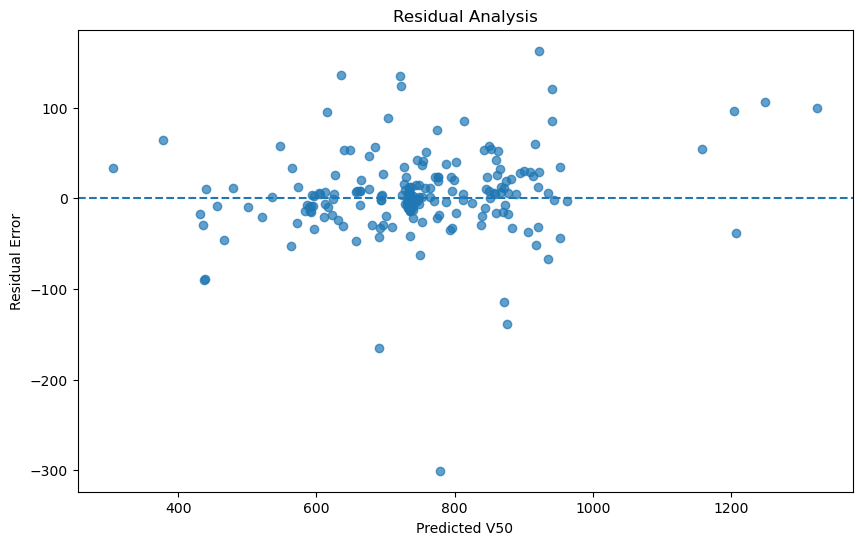

In [37]:
plt.figure(figsize=(10, 6))

plt.scatter(
    best_predictions,
    evaluation_df["Error"],
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted V50")
plt.ylabel("Residual Error")

plt.title("Residual Analysis")

plt.show()


5-Fold Cross Validation

In [38]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Linear Regression CV

In [39]:
linear_cv = cross_val_score(
    linear_model,
    X,
    y,
    cv=kf,
    scoring="neg_root_mean_squared_error"
)

print("Linear Regression CV RMSE:")
print(-linear_cv)

print("Mean:", -linear_cv.mean())
print("Std :", linear_cv.std())

Linear Regression CV RMSE:
[4.28976811e+10 3.53724421e+11 9.37707111e+09 6.11306780e+13
 2.19261165e+12]
Mean: 12745857765493.514
Std : 24205825486967.957


Decision Tree CV

In [40]:
tree_cv = cross_val_score(
    decision_tree_model,
    X,
    y,
    cv=kf,
    scoring="neg_root_mean_squared_error"
)

print("Decision Tree CV RMSE:")
print(-tree_cv)

print("Mean:", -tree_cv.mean())
print("Std :", tree_cv.std())

Decision Tree CV RMSE:
[60.34168979 55.05185972 44.1243391  44.10716414 54.66780027]
Mean: 51.65857060459962
Std : 6.476956337013266


Random Forest CV

In [41]:
rf_cv = cross_val_score(
    random_forest_model,
    X,
    y,
    cv=kf,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

print("Random Forest CV RMSE:")
print(-rf_cv)

print("Mean:", -rf_cv.mean())
print("Std :", rf_cv.std())

Random Forest CV RMSE:
[46.00622421 44.98292691 40.66671396 28.81732804 45.04881117]
Mean: 41.104400858380345
Std : 6.415495890948236


Gradient Boosting CV

In [42]:
gradient_cv = cross_val_score(
    gradient_model,
    X,
    y,
    cv=kf,
    scoring="neg_root_mean_squared_error"
)

print("Gradient Boosting CV RMSE:")
print(-gradient_cv)

print("Mean:", -gradient_cv.mean())
print("Std :", gradient_cv.std())

Gradient Boosting CV RMSE:
[50.59194872 55.17089722 50.93308241 45.67884397 50.32134254]
Mean: 50.53922297476552
Std : 3.009354333449639


Cross-validation comparison

In [43]:
cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Mean CV RMSE": [
        -linear_cv.mean(),
        -tree_cv.mean(),
        -rf_cv.mean(),
        -gradient_cv.mean()
    ],

    "CV Std": [
        linear_cv.std(),
        tree_cv.std(),
        rf_cv.std(),
        gradient_cv.std()
    ]
})

cv_results = cv_results.sort_values(
    by="Mean CV RMSE"
)

display(cv_results)

,Model,Mean CV RMSE,CV Std
2,Random Forest,4.110440e+01,6.415496e+00
3,Gradient Boosting,5.053922e+01,3.009354e+00
1,Decision Tree,5.165857e+01,6.476956e+00
0,Linear Regression,1.274586e+13,2.420583e+13


Train final model

In [44]:
model_objects = {
    "Linear Regression": linear_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_model
}

best_model = model_objects[best_model_name]

print("Final selected model:", best_model_name)

Final selected model: Random Forest


In [45]:
best_model.fit(X, y)

print("Final model trained successfully.")

Final model trained successfully.


Save the ML model

In [46]:
joblib.dump(
    best_model,
    "ballistics_v50_model.pkl"
)

print("Model saved as ballistics_v50_model.pkl")

Model saved as ballistics_v50_model.pkl


Test a prediction

In [47]:
sample = X.iloc[[0]]

actual_value = y.iloc[0]

predicted_value = best_model.predict(sample)[0]

print("Actual V50:", actual_value)
print("Predicted V50:", predicted_value)
print("Absolute Error:", abs(actual_value - predicted_value))

Actual V50: 348.0
Predicted V50: 402.4810714285714
Absolute Error: 54.4810714285714
